# Рекомендательные системы

Рекомендательная система — это приложение в области анализа данных, используемое для прогнозирования или предложения товаров клиентам на основе их истории покупок или просмотра веб-сайтов.гих компаний


- По своей сути, рекомендательная система использует алгоритм машинного обучения, задача которого — предсказать оценки пользователей для конкретного объекта.
- Она основана на сходстве, определяемом по объектам или пользователям, которые ранее оценивали эти объекты.
- Идея заключается в том, что пользователи схожих типов, скорее всего, будут иметь схожие оценки для набора объектов.
- Рекомендательные системы находят широкое применение.
- Многие крупные технологические компании используют системы рекомендаций в той или иной форме, чтобы рекомендовать товары своим клиентам.
- Возможность рекомендовать пользователям релевантные товары или услуги может быть очень прибыльной для компании. Поэтому подобные приложения так распространены среди многих компаний


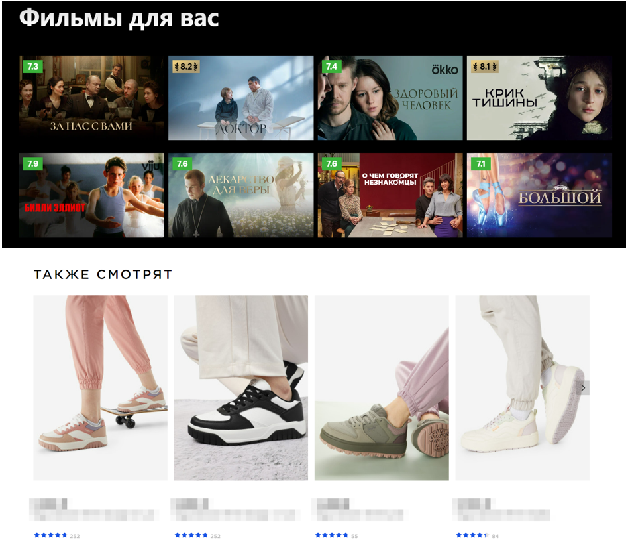

### Как устроены рекомендательные системы

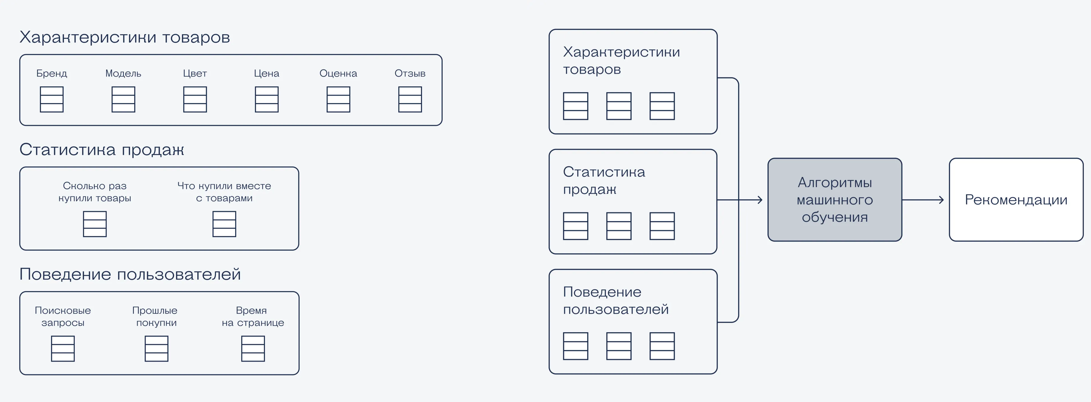

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

**Загрузка данных**

In [2]:
books=pd.read_csv("Books.csv")
rating=pd.read_csv("Ratings.csv")
users=pd.read_csv("Users.csv")

C:\Users\poula\AppData\Local\Temp\ipykernel_3776\2493730944.py:1: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  books=pd.read_csv("Books.csv")


In [3]:
books.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [4]:
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [5]:
rating.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [6]:
print(books.shape)
print(rating.shape)
print(users.shape)

(271360, 8)
(1149780, 3)
(278858, 3)


In [7]:
df1=users.merge(rating,on='User-ID')

In [8]:
df1

,User-ID,Location,Age,ISBN,Book-Rating
0,2,"stockton, california, usa",18.0,0195153448,0
1,7,"washington, dc, usa",NaN,034542252,0
2,8,"timmins, ontario, canada",NaN,0002005018,5
3,8,"timmins, ontario, canada",NaN,0060973129,0
4,8,"timmins, ontario, canada",NaN,0374157065,0
...,...,...,...,...,...
1149775,278854,"portland, oregon, usa",NaN,0425163393,7
1149776,278854,"portland, oregon, usa",NaN,0515087122,0
1149777,278854,"portland, oregon, usa",NaN,0553275739,6
1149778,278854,"portland, oregon, usa",NaN,0553578596,0


In [9]:
data=df1.merge(books,on='ISBN')

In [10]:
data.head()

,User-ID,Location,Age,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,2,"stockton, california, usa",18.0,0195153448,0,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,8,"timmins, ontario, canada",NaN,0002005018,5,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,8,"timmins, ontario, canada",NaN,0060973129,0,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,8,"timmins, ontario, canada",NaN,0374157065,0,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,8,"timmins, ontario, canada",NaN,0393045218,0,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


In [11]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1031136 entries, 0 to 1031135
Data columns (total 12 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   User-ID              1031136 non-null  int64  
 1   Location             1031136 non-null  object 
 2   Age                  753301 non-null   float64
 3   ISBN                 1031136 non-null  object 
 4   Book-Rating          1031136 non-null  int64  
 5   Book-Title           1031136 non-null  object 
 6   Book-Author          1031134 non-null  object 
 7   Year-Of-Publication  1031136 non-null  object 
 8   Publisher            1031134 non-null  object 
 9   Image-URL-S          1031136 non-null  object 
 10  Image-URL-M          1031136 non-null  object 
 11  Image-URL-L          1031132 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 94.4+ MB


**Обработка данных**

In [12]:
df=data.copy()
df.dropna(inplace=True)
df.reset_index(drop=True,inplace=True)

In [13]:
df.drop(columns=["ISBN","Year-Of-Publication","Image-URL-S","Image-URL-M"],axis=1,inplace=True)
df.drop(index=df[df["Book-Rating"]==0].index,inplace=True)

In [14]:
df.shape

(269616, 8)

In [15]:
import re  

df["Book-Title"] = df["Book-Title"].apply(lambda x: re.sub("[\W_]+", " ", x).strip())
df.head()

,User-ID,Location,Age,Book-Rating,Book-Title,Book-Author,Publisher,Image-URL-L
2,19,"weston, ,",14.0,7,Prague A Novel,ARTHUR PHILLIPS,Random House Trade Paperbacks,http://images.amazon.com/images/P/0375759778.0...
5,42,"appleton, wisconsin, usa",17.0,7,From the Corner of His Eye,Dean Koontz,Bantam Books,http://images.amazon.com/images/P/0553582747.0...
8,44,"black mountain, north carolina, usa",51.0,8,This Year It Will Be Different And Other Stories,Maeve Binchy,Dell,http://images.amazon.com/images/P/0440223571.0...
11,51,"renton, washington, usa",34.0,9,The Street Lawyer,JOHN GRISHAM,Dell,http://images.amazon.com/images/P/0440225701.0...
12,56,"cheyenne, wyoming, usa",24.0,7,LONESOME DOVE,Larry McMurtry,Pocket,http://images.amazon.com/images/P/0671623249.0...


### **Система рекомендаций на основе взвешенных рейтингов** 

Рекомендательная система, основанная на популярности

Демографическая фильтрация — система предлагает обобщенные рекомендации каждому пользователю на основе популярности книг и/или жанра. Система рекомендует одни и те же книги пользователям со схожими демографическими характеристиками. Поскольку каждый пользователь индивидуален, этот подход считается слишком упрощенным. Основная идея системы заключается в том, что более популярные и высоко оцененные пользователми книги с большей вероятностью понравятся среднестатистической аудитории

In [16]:
avg_ratings = df.groupby('Book-Title')['Book-Rating'].mean().reset_index().rename(columns={'Book-Rating': 'avg_rating'})

avg=pd.DataFrame(avg_ratings).sort_values('avg_rating',ascending=False)

In [17]:
avg.head(10)

,Book-Title,avg_rating
4,1 000 Makers of the Millennium The Men and Wom...,10.0
5,1 000 Marbles A Little Something About Preciou...,10.0
10,1 001 Computer Hints amp Tips An A To Z Guide ...,10.0
108425,touch the flame,10.0
15,1 001 Old Time Garden Tips Timeless Bits of Wi...,10.0
58681,No One But You Lovers Under Cover Harlequin In...,10.0
63,100 Cross Stitch Christmas Ornaments,10.0
33,10 000 Ways to Say I Love You The Biggest Coll...,10.0
35,10 American History Plays for the Classroom Gr...,10.0
39,10 Gebote fÃ Â¼r anspruchsvolle Frauen,10.0


In [18]:
cnt_ratings = df.groupby('Book-Title')['Book-Rating'].count().reset_index().rename(columns={'Book-Rating': 'count_rating'})

cnt=pd.DataFrame(cnt_ratings).sort_values('count_rating',ascending=False)

In [19]:
cnt.head(10)

,Book-Title,count_rating
88395,The Lovely Bones A Novel,473
105900,Wild Animus,473
82312,The Da Vinci Code,380
93122,The Secret Life of Bees,280
12489,Bridget Jones s Diary,261
6439,Angels amp Demons,258
48712,Life of Pi,252
89747,The Nanny Diaries A Novel,246
36310,Harry Potter and the Chamber of Secrets Book 2,246
23918,Divine Secrets of the Ya Ya Sisterhood A Novel,242


In [20]:
popularite=avg.merge(cnt,on='Book-Title')

In [21]:
popularite.head(10)

,Book-Title,avg_rating,count_rating
0,1 000 Makers of the Millennium The Men and Wom...,10.0,1
1,1 000 Marbles A Little Something About Preciou...,10.0,1
2,1 001 Computer Hints amp Tips An A To Z Guide ...,10.0,1
3,touch the flame,10.0,1
4,1 001 Old Time Garden Tips Timeless Bits of Wi...,10.0,1
5,No One But You Lovers Under Cover Harlequin In...,10.0,1
6,100 Cross Stitch Christmas Ornaments,10.0,1
7,10 000 Ways to Say I Love You The Biggest Coll...,10.0,1
8,10 American History Plays for the Classroom Gr...,10.0,1
9,10 Gebote fÃ Â¼r anspruchsvolle Frauen,10.0,1


Классическая формула IMDb / Bayesian Average для «взвешенного рейтинга». Применяется, чтобы книги с 1–2 оценками «5.0» не обгоняли книги с 1000 оценок «4.5»


V – количество оценок у конкретной книги

R – средний рейтинг этой книги

m – «порог доверия» — сколько оценок нужно, чтобы рейтинг считался надёжным

c - средний рейтинг по всем книгам


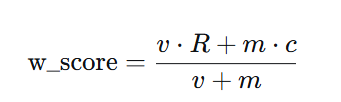

m — порог доверия. Здесь выбран как 90-й процентиль числа оценок: 90% книг имеют меньше оценок, чем m, и только топ-10% — больше.
Смысл: чтобы «обогнать» порог и получить рейтинг, близкий к своему настоящему R, книга должна набрать как минимум столько оценок, сколько набрали 90% лучших по популярности книг. Это довольно строгий порог — он сильно тянет вниз рейтинги редких книг.


In [22]:
v = popularite["count_rating"]
R = popularite["avg_rating"]
m = v.quantile(0.90)
c = R.mean()
popularite['w_score']=((v*R) + (m*c)) / (v+m)

In [23]:
popularite["count_rating"].describe()

count    108449.000000
mean          2.486109
std           6.988328
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max         473.000000
Name: count_rating, dtype: float64

In [24]:
pop_sort=popularite.sort_values('w_score',ascending=False)

In [25]:
pop_sort

,Book-Title,avg_rating,count_rating,w_score
15827,Harry Potter and the Chamber of Secrets Postca...,9.842105,19,9.459806
16117,The Hobbit,9.526316,38,9.347037
17182,The Return of the King The Lord of the Rings P...,9.416667,84,9.336086
17227,The Two Towers The Lord of the Rings Part 2,9.370370,108,9.308710
15825,Dilbert A Book of Postcards,9.900000,10,9.255396
...,...,...,...,...
104719,Coal A Human History,4.764706,17,5.313121
104971,Confessions of a Sociopathic Social Climber Th...,4.416667,12,5.223471
104972,The Sexual Life of Catherine M,4.357143,14,5.087530
107682,Black Coffee Blues,2.800000,5,4.952838


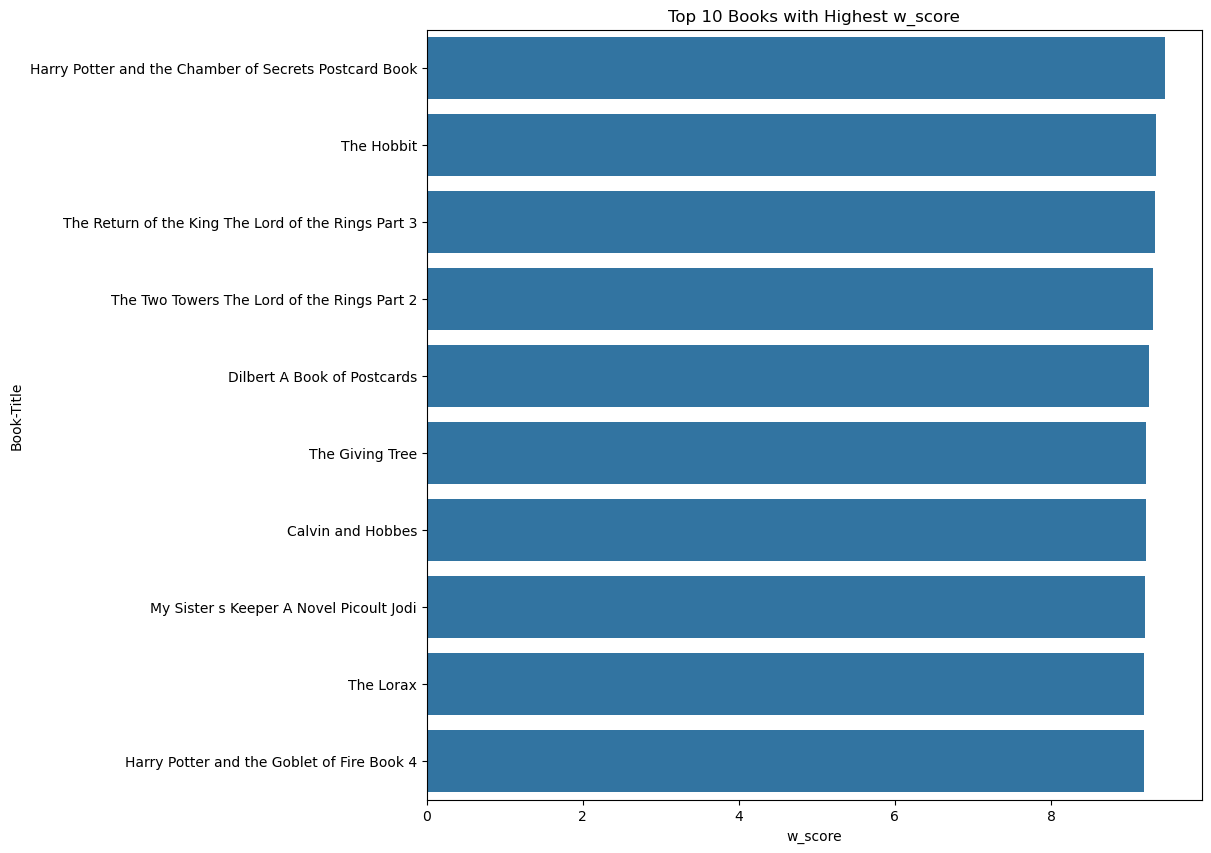

In [26]:
top_10_books = pop_sort.head(10)

plt.figure(figsize=(10, 10))
sns.barplot(x='w_score', y='Book-Title', data=top_10_books)
plt.xlabel('w_score')
plt.ylabel('Book-Title')
plt.title('Top 10 Books with Highest w_score')
plt.show()

# Рекомендательная система на основе коллаборативной фильтрации

**Фильтрация на основе пользователей** — эти системы рекомендуют пользователю товары, которые понравились похожим пользователям. Для измерения сходства между двумя пользователями можно использовать либо коэффициент корреляции Пирсона, либо косинусное сходство.

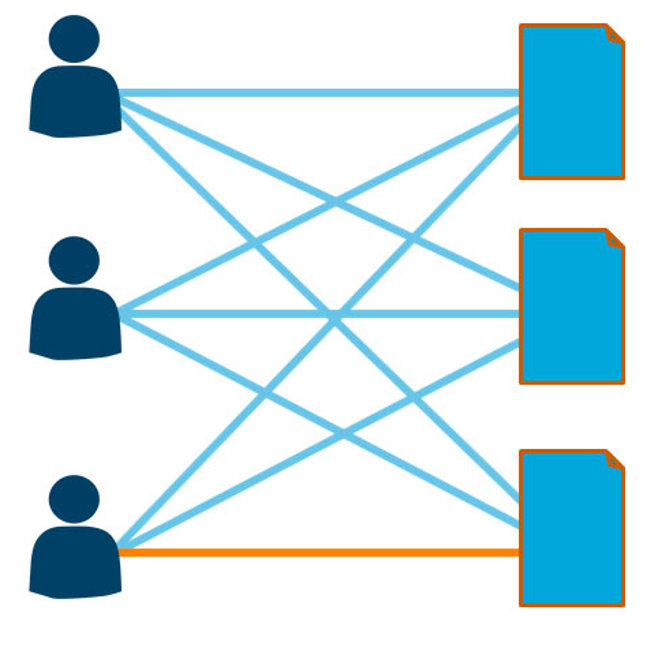

Алгоритм коллаборативной фильтрации предлагает пользователям в качестве рекомендаций то, что часто смотрели вместе с просмотренными им объявлениями. 
Допустим пользователь 1 и пользователь 2 просмотрели объявления a, b, c, а пользователь 3 просмотрел объявления a и с. В таком случае вероятно, что объявление b также заинтересует пользователя 3. 


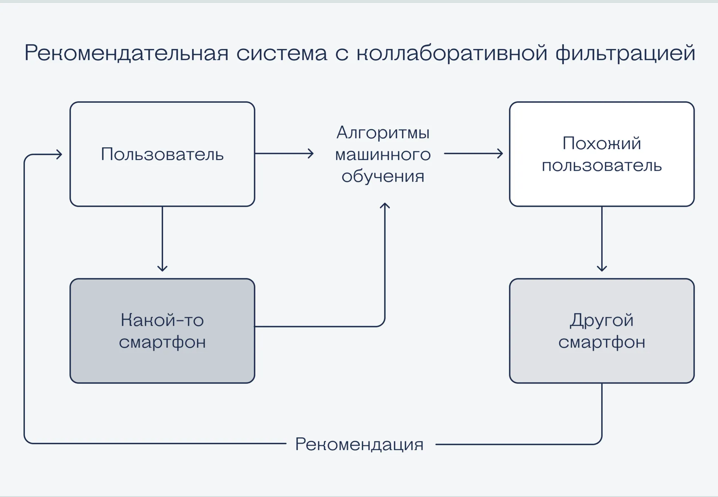

## **Cистема рекомендаций по коллаборативной фильтрации (с использованием корреляции)**

In [27]:
new_df=df[df['User-ID'].map(df['User-ID'].value_counts()) > 200]  

In [28]:
new_df

,User-ID,Location,Age,Book-Rating,Book-Title,Book-Author,Publisher,Image-URL-L
7841,4385,"albq, new mexico, usa",33.0,10,The Bandit s Lady Harper Monogram,Maureen Child,Harper Mass Market Paperbacks (Mm),http://images.amazon.com/images/P/0061083402.0...
7843,4385,"albq, new mexico, usa",33.0,9,Fault Lines,Anne Rivers Siddons,HarperTorch,http://images.amazon.com/images/P/0061093343.0...
7844,4385,"albq, new mexico, usa",33.0,10,Society of the Mind A Cyberthriller,Eric L. Harry,Harper Mass Market Paperbacks (Mm),http://images.amazon.com/images/P/0061096156.0...
7846,4385,"albq, new mexico, usa",33.0,10,Die Hard With a Vengeance A Novel,D. Chiel,St Martins Pr,http://images.amazon.com/images/P/0312956762.0...
7847,4385,"albq, new mexico, usa",33.0,10,Circle of Stars,Anna Lee Waldo,St. Martin's Paperbacks,http://images.amazon.com/images/P/0312980353.0...
...,...,...,...,...,...,...,...,...
743159,274061,"gahanna/columbus, ohio, usa",26.0,10,Cardcaptor Sakura Number 5,Clamp,Tokyopop,http://images.amazon.com/images/P/1892213737.0...
743160,274061,"gahanna/columbus, ohio, usa",26.0,10,Clover 2,Clamp,Tokyopop,http://images.amazon.com/images/P/189221394X.0...
743161,274061,"gahanna/columbus, ohio, usa",26.0,10,Clover 3,Clamp,Tokyopop,http://images.amazon.com/images/P/1892213958.0...
743162,274061,"gahanna/columbus, ohio, usa",26.0,10,Clover Clover 4,Clamp,TokyoPop,http://images.amazon.com/images/P/1892213966.0...


In [29]:
users_pivot=new_df.pivot_table(index=["User-ID"],columns=["Book-Title"],values="Book-Rating")
users_pivot.fillna(0,inplace=True)

In [30]:
users_pivot.head()

Book-Title,01 01 00 The Novel of the Millennium,1 000 Makers of the Millennium The Men and Women Who Have Shaped the Last 1 000 Years,10 000 Answers The Ultimate Trivia Encyclopedia,10 000 Things to Praise God for,10 000 dreams interpreted A dictionary of dreams,10 Bad Choices That Ruin Black Women s Lives,10 Lb Penalty,10 Minutes Till Bedtime,10 Things You Should Know About Dinosaurs 10 Things You Should Know series,100 Best Loved Poems Dover Thrift Editions,...,and the shadows took him A Novel,christmas on snowbird mountain,e,good girls do Sex Chronicles of a Shameless Generation,one hundred years of solitude,operation mistletoe the special agents,stardust,the Dark Light Years,together by christmas,Â Eres tu mi mamÃ Are You My Mother
User-ID,,,,,,,,,,,,,,,,,,,,,
4385,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6251,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7346,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13552,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16634,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [31]:
def same_books(book):
    users_vote_film=users_pivot[book]
    similar_with=users_pivot.corrwith(users_vote_film)
    similar_with = pd.DataFrame(similar_with, columns=['correlation'])
    print(similar_with)
    df=similar_with.sort_values('correlation',ascending=False).head(10)
    print(df)
    df_sort=df[df['correlation']>0.8]
    return df_sort

In [32]:
same_books('10 Lb Penalty')

                                                    correlation
Book-Title                                                     
01 01 00 The Novel of the Millennium                  -0.020590
1 000 Makers of the Millennium The Men and Wome...    -0.020590
10 000 Answers The Ultimate Trivia Encyclopedia       -0.020590
10 000 Things to Praise God for                       -0.020590
10 000 dreams interpreted A dictionary of dreams      -0.020590
...                                                         ...
operation mistletoe the special agents                -0.020590
stardust                                              -0.036034
the Dark Light Years                                  -0.020590
together by christmas                                 -0.020590
Â Eres tu mi mamÃ Are You My Mother                   -0.020590

[28675 rows x 1 columns]
                                             correlation
Book-Title                                              
10 Lb Penalty               

,correlation
Book-Title,
10 Lb Penalty,1.000000
Stick,0.841483
To the Hilt,0.841187


In [33]:
same_books('The Hobbit')

                                                    correlation
Book-Title                                                     
01 01 00 The Novel of the Millennium                  -0.020621
1 000 Makers of the Millennium The Men and Wome...    -0.020621
10 000 Answers The Ultimate Trivia Encyclopedia       -0.020621
10 000 Things to Praise God for                       -0.020621
10 000 dreams interpreted A dictionary of dreams      -0.020621
...                                                         ...
operation mistletoe the special agents                -0.020621
stardust                                              -0.036089
the Dark Light Years                                  -0.020621
together by christmas                                 -0.020621
Â Eres tu mi mamÃ Are You My Mother                   -0.020621

[28675 rows x 1 columns]
                                                    correlation
Book-Title                                                     
The Hobbit    

,correlation
Book-Title,
The Hobbit,1.000000
Hawaii,0.810473


### **Коллаборативная фильтрация: модель NearestNeighbours из scikit-learn для системы рекомендаций**

Коллаборативная фильтрация — популярный метод построения систем рекомендаций, основанных на предпочтениях и поведении пользователей. 
Методы коллаборативной фильтрации дают рекомендации, используя шаблоны и отношения между пользователями и объектами.

Коллаборативная фильтрация на основе пользователей. Этот подход идентифицирует пользователей, похожих на целевого пользователя, на основе их предпочтений, а затем рекомендует элементы, которые понравились этим похожим пользователям. Предполагается, что если пользователи A и B имели схожие предпочтения в прошлом, то то, что нравится одному из них, может понравиться и другому.

In [34]:
df.head()

,User-ID,Location,Age,Book-Rating,Book-Title,Book-Author,Publisher,Image-URL-L
2,19,"weston, ,",14.0,7,Prague A Novel,ARTHUR PHILLIPS,Random House Trade Paperbacks,http://images.amazon.com/images/P/0375759778.0...
5,42,"appleton, wisconsin, usa",17.0,7,From the Corner of His Eye,Dean Koontz,Bantam Books,http://images.amazon.com/images/P/0553582747.0...
8,44,"black mountain, north carolina, usa",51.0,8,This Year It Will Be Different And Other Stories,Maeve Binchy,Dell,http://images.amazon.com/images/P/0440223571.0...
11,51,"renton, washington, usa",34.0,9,The Street Lawyer,JOHN GRISHAM,Dell,http://images.amazon.com/images/P/0440225701.0...
12,56,"cheyenne, wyoming, usa",24.0,7,LONESOME DOVE,Larry McMurtry,Pocket,http://images.amazon.com/images/P/0671623249.0...


In [35]:
users_pivot

Book-Title,01 01 00 The Novel of the Millennium,1 000 Makers of the Millennium The Men and Women Who Have Shaped the Last 1 000 Years,10 000 Answers The Ultimate Trivia Encyclopedia,10 000 Things to Praise God for,10 000 dreams interpreted A dictionary of dreams,10 Bad Choices That Ruin Black Women s Lives,10 Lb Penalty,10 Minutes Till Bedtime,10 Things You Should Know About Dinosaurs 10 Things You Should Know series,100 Best Loved Poems Dover Thrift Editions,...,and the shadows took him A Novel,christmas on snowbird mountain,e,good girls do Sex Chronicles of a Shameless Generation,one hundred years of solitude,operation mistletoe the special agents,stardust,the Dark Light Years,together by christmas,Â Eres tu mi mamÃ Are You My Mother
User-ID,,,,,,,,,,,,,,,,,,,,,
4385,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6251,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7346,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13552,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16634,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264321,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0
265889,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
269566,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [36]:
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

# Подготовка данных и модели
book_df_matrix = csr_matrix(users_pivot.values).T
model_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn.fit(book_df_matrix)

def find_similar_books(book_name, num_neighbors=10, model=model_knn):
    book_index = users_pivot.T.index.get_loc(book_name)
    book_vector = book_df_matrix[book_index]
    distances, indices = model.kneighbors(book_vector, n_neighbors=num_neighbors+1)
    
    similar_indices = indices[0][1:]
    similar_distances = distances[0][1:]
    
    list_similar_books = users_pivot.T.index[similar_indices].tolist()
    
    return pd.DataFrame({
        "Book": list_similar_books,
        "Distance": similar_distances
    })

In [37]:
input_book = 'The Hobbit'
find_similar_books(input_book)

,Book,Distance
0,Hawaii,0.184632
1,Covenant,0.247227
2,The Return of the King The Lord of the Rings P...,0.281424
3,Foundation and Empire Foundation Novels Paperback,0.289331
4,I Robot,0.299174
5,Second Foundation Foundation Novels Paperback,0.311163
6,Foundation Foundation Novels Paperback,0.322292
7,The Postman Bantam Classics,0.357961
8,Dune Messiah Dune Chronicles Book 2,0.372946
9,When Heaven Weeps A Novel,0.422650


In [38]:
input_book = "I Robot"  
find_similar_books(input_book)

,Book,Distance
0,Hawaii,0.145228
1,Covenant,0.211107
2,The Martian Chronicles,0.232018
3,Foundation and Empire Foundation Novels Paperback,0.252917
4,Second Foundation Foundation Novels Paperback,0.275869
5,Foundation Foundation Novels Paperback,0.285594
6,The Hobbit,0.299174
7,The Postman Bantam Classics,0.325064
8,Night over Water,0.346916
9,Seven Deadly Sins amp Cardinal Virtues of Scie...,0.361123


In [39]:
def find_favorite_books(User_id, num_books=10):
    user_ratings = users_pivot.loc[User_id]    
    top_books = user_ratings.sort_values(ascending=False).head(num_books)    
    return pd.DataFrame({
        "favorite books": top_books.index,
        "rating": top_books.values
    })

In [40]:
User_id= 7346  
find_favorite_books(User_id)

,favorite books,rating
0,Aunt Dimity s Death Aunt Dimity Paperback,10.0
1,The Warlock in Spite of Himself,10.0
2,Not a Penny More 4,10.0
3,The Thin Woman,10.0
4,Mere Christianity A revised and enlarged editi...,10.0
5,Dragonsinger,10.0
6,Dragonquest,10.0
7,101 Dalmatians,10.0
8,To Say Nothing of the Dog,10.0
9,Charlotte s Web,10.0


In [41]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors
from scipy.sparse import csr_matrix

user_item_matrix = csr_matrix(users_pivot.values)
model_user_knn = NearestNeighbors(metric='cosine', algorithm='brute')
model_user_knn.fit(user_item_matrix)


def find_user_recommendations(User_id, num_neighbors=20, num_books=10):
    user_index = users_pivot.index.get_loc(User_id)
    
    # 1. Ищем похожих пользователей
    distances, indices = model_user_knn.kneighbors(
        user_item_matrix[user_index],
        n_neighbors=num_neighbors + 1
    )
    similar_user_indices = indices[0][1:]
    similar_distances   = distances[0][1:]
    
    # 2. Оценки похожих пользователей (DataFrame: users × books)
    similar_ratings = users_pivot.iloc[similar_user_indices]
    
    # 3. Взвешенное среднее: чем ближе пользователь (меньше distance), тем больше вес
    weights = 1 / (similar_distances + 1e-9)          # избегаем деления на 0
    weighted_scores = similar_ratings.T.dot(weights) / weights.sum()
    
    # 4. Исключаем книги, которые целевой пользователь уже оценил (> 0)
    target_ratings = users_pivot.iloc[user_index]
    unread = target_ratings[target_ratings == 0].index
    candidates = weighted_scores.loc[unread]
    
    # 5. Топ-N по взвешенной оценке
    top_books = candidates.sort_values(ascending=False).head(num_books)
    
    return pd.DataFrame({
        "Recommended Books": top_books.index,
        "Score": top_books.values.round(3)
    })

In [42]:
User_id= 7346  
find_user_recommendations(User_id)

,Recommended Books,Score
0,Harry Potter and the Chamber of Secrets Book 2,2.697
1,Bridget Jones s Diary,2.499
2,The Hours A Novel,2.475
3,The Notebook,2.397
4,House of Sand and Fog,2.205
5,Girl Interrupted,2.141
6,The Catcher in the Rye,2.064
7,The Red Tent Bestselling Backlist,2.062
8,Pigs in Heaven,2.009
9,The Alienist,1.960


In [43]:
User_id= 13552  
find_user_recommendations(User_id)

,Recommended Books,Score
0,Heartbreaker,2.957
1,The Gift,2.772
2,Cujo,2.669
3,Public Secrets,2.654
4,Purity in Death,2.650
5,Carnal Innocence,2.612
6,The Notebook,2.576
7,Montana Sky,2.403
8,Gentle Rogue Malory Novels Paperback,2.336
9,Pet Sematary,2.335


**Косинусное сходство**

In [44]:
users_pivot.head()

Book-Title,01 01 00 The Novel of the Millennium,1 000 Makers of the Millennium The Men and Women Who Have Shaped the Last 1 000 Years,10 000 Answers The Ultimate Trivia Encyclopedia,10 000 Things to Praise God for,10 000 dreams interpreted A dictionary of dreams,10 Bad Choices That Ruin Black Women s Lives,10 Lb Penalty,10 Minutes Till Bedtime,10 Things You Should Know About Dinosaurs 10 Things You Should Know series,100 Best Loved Poems Dover Thrift Editions,...,and the shadows took him A Novel,christmas on snowbird mountain,e,good girls do Sex Chronicles of a Shameless Generation,one hundred years of solitude,operation mistletoe the special agents,stardust,the Dark Light Years,together by christmas,Â Eres tu mi mamÃ Are You My Mother
User-ID,,,,,,,,,,,,,,,,,,,,,
4385,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6251,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7346,0.0,0.0,0.0,8.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13552,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
16634,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [45]:
from sklearn.metrics.pairwise import cosine_similarity 

In [46]:
similarity_score = cosine_similarity(users_pivot.T)

In [47]:
similarity_score.shape

(28675, 28675)

In [48]:
similarity_score

array([[1., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 1., 0.],
       [0., 0., 0., ..., 0., 0., 1.]])

In [49]:
users_pivot2 = users_pivot.T

In [50]:
def recommend(book_name):
    if book_name not in users_pivot2.index:
        return f"Книга '{book_name}' не найдена в базе рекомендаций."
    
    index = np.where(users_pivot2.index == book_name)[0][0]
    
    similar_books = sorted(list(enumerate(similarity_score[index])), key=lambda x: x[1], reverse=True)[1:11]
    
    data = []
    
    for i in similar_books:
        book_title = users_pivot2.index[i[0]]
        score = i[1]
        
        temp_df = books[books['Book-Title'] == book_title]
        
        if not temp_df.empty:
            author = temp_df['Book-Author'].values[0]
            image_url = temp_df['Image-URL-M'].values[0]
            
            data.append({
                "Book-Title": book_title,
                "Book-Author": author,
                "Image-URL": image_url,
                "Similarity Score": score
            })

    return pd.DataFrame(data)

In [51]:
recommend("Message in a Bottle")

,Book-Title,Book-Author,Image-URL,Similarity Score
0,Evergreen,Belva Plain,http://images.amazon.com/images/P/0440132789.0...,0.611418
1,Happy Are Those Who Thirst for Justice,Andrew M. Greeley,http://images.amazon.com/images/P/0446349461.0...,0.606696
2,Sick Puppy,Carl Hiaasen,http://images.amazon.com/images/P/0446604666.0...,0.580042
3,Destiny,Flavia,http://images.amazon.com/images/P/0768322413.0...,0.576450
4,PETALS ON WIND,V. C. Andrews,http://images.amazon.com/images/P/0671829777.0...,0.566063
5,The Notebook,Nicholas Sparks,http://images.amazon.com/images/P/0446605239.0...,0.564324
6,Pay It Forward,Catherine Ryan Hyde,http://images.amazon.com/images/P/0743412028.0...,0.560707
7,Silver Wedding,Maeve Binchy,http://images.amazon.com/images/P/0440207770.0...,0.553610


In [52]:
recommend("The Notebook")

,Book-Title,Book-Author,Image-URL,Similarity Score
0,The Rescue,Nicholas Sparks,http://images.amazon.com/images/P/0446610399.0...,0.684624
1,A Walk to Remember,Nicholas Sparks,http://images.amazon.com/images/P/0446608955.0...,0.656011
2,Wish You Well,David Baldacci,http://images.amazon.com/images/P/0446527165.0...,0.622133
3,Message in a Bottle,Nicholas Sparks,http://images.amazon.com/images/P/0446523569.0...,0.564324
4,Snow White and the Seven Dwarfs,Little Golden Staff,http://images.amazon.com/images/P/0307010368.0...,0.537505
5,PETALS ON WIND,V. C. Andrews,http://images.amazon.com/images/P/0671829777.0...,0.535782
6,Timepiece,Richard Paul Evans,http://images.amazon.com/images/P/0671008978.0...,0.532426
7,Nights in Rodanthe,Nicholas Sparks,http://images.amazon.com/images/P/0446531332.0...,0.531287


In [53]:
recommend("1984")

,Book-Title,Book-Author,Image-URL,Similarity Score
0,Waiting,Frank M. Robinson,http://images.amazon.com/images/P/0812541642.0...,0.593176
1,Fahrenheit 451,Ray Bradbury,http://images.amazon.com/images/P/3257208626.0...,0.583212
2,Lying Awake,Mark Salzman,http://images.amazon.com/images/P/0375406328.0...,0.581762
3,The Catcher in the Rye,J.D. Salinger,http://images.amazon.com/images/P/0316769487.0...,0.550257
4,Cat and Mouse,James Patterson,http://images.amazon.com/images/P/0316693294.0...,0.523097


In [54]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 100)

In [55]:
books_file = "Books.csv"
ratings_file = "Ratings.csv"

if os.path.exists("Users.csv"):
    users_file = "Users.csv"
elif os.path.exists("Users (1).csv"):
    users_file = "Users (1).csv"
else:
    users_file = None

books = pd.read_csv(books_file, encoding="latin-1", low_memory=False)
ratings = pd.read_csv(ratings_file, encoding="latin-1", low_memory=False)

if users_file:
    users = pd.read_csv(users_file, encoding="latin-1", low_memory=False)
else:
    users = pd.DataFrame()

print("Книги:", books.shape)
print("Оценки:", ratings.shape)
print("Пользователи:", users.shape if not users.empty else "файл не найден — для алгоритмов не обязателен")

Книги: (271360, 8)
Оценки: (1149780, 3)
Пользователи: (278858, 3)


In [56]:
display(books.head())
display(ratings.head())
if not users.empty:
    display(users.head())

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg
3,0374157065,Flu: The Story of the Great Influenza Pandemic of 1918 and the Search for the Virus That Caused It,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0374157065.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0374157065.01.LZZZZZZZ.jpg
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.01.THUMBZZZ.jpg,http://images.amazon.com/images/P/0393045218.01.MZZZZZZZ.jpg,http://images.amazon.com/images/P/0393045218.01.LZZZZZZZ.jpg


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [57]:
print("Столбцы книг:", books.columns.tolist())
print("Столбцы оценок:", ratings.columns.tolist())
print("Пропуски в таблице книг:")
display(books.isna().sum().sort_values(ascending=False).head(10))
print("Количество оценок по шкале:")
display(ratings["Book-Rating"].value_counts().sort_index())

Столбцы книг: ['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']
Столбцы оценок: ['User-ID', 'ISBN', 'Book-Rating']
Пропуски в таблице книг:


Image-URL-L            3
Book-Author            2
Publisher              2
ISBN                   0
Year-Of-Publication    0
Book-Title             0
Image-URL-S            0
Image-URL-M            0
dtype: int64

Количество оценок по шкале:


Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

In [58]:
books_clean = books[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication", "Publisher"]].copy()
ratings_clean = ratings[["User-ID", "ISBN", "Book-Rating"]].copy()

books_clean = books_clean.dropna(subset=["ISBN", "Book-Title"])
ratings_clean = ratings_clean.dropna(subset=["User-ID", "ISBN", "Book-Rating"])

books_clean["ISBN"] = books_clean["ISBN"].astype(str).str.strip()
ratings_clean["ISBN"] = ratings_clean["ISBN"].astype(str).str.strip()
ratings_clean["User-ID"] = pd.to_numeric(ratings_clean["User-ID"], errors="coerce")
ratings_clean["Book-Rating"] = pd.to_numeric(ratings_clean["Book-Rating"], errors="coerce")
ratings_clean = ratings_clean.dropna(subset=["User-ID", "Book-Rating"])

ratings_clean = ratings_clean[ratings_clean["Book-Rating"].between(1, 10)]
ratings_clean = ratings_clean.drop_duplicates(subset=["User-ID", "ISBN"], keep="last")

books_clean = books_clean.drop_duplicates(subset=["ISBN"], keep="first")
books_clean["Book-Title"] = books_clean["Book-Title"].astype(str).str.strip()
books_clean["Book-Author"] = books_clean["Book-Author"].fillna("Автор не указан")

print("Книг после очистки:", len(books_clean))
print("Оценок после очистки:", len(ratings_clean))
print("Уникальных пользователей:", ratings_clean["User-ID"].nunique())

Книг после очистки: 271359
Оценок после очистки: 433671
Уникальных пользователей: 77805


In [59]:
book_stats = ratings_clean.groupby("ISBN")["Book-Rating"].agg(
    average_rating="mean",
    ratings_count="count"
).reset_index()

popular_books = book_stats.merge(books_clean, on="ISBN", how="left")
popular_books["Book-Title"] = popular_books["Book-Title"].fillna("Название не указано")

min_votes = popular_books["ratings_count"].quantile(0.90)
global_average = ratings_clean["Book-Rating"].mean()

popular_books["weighted_rating"] = (
    (popular_books["ratings_count"] * popular_books["average_rating"] +
     min_votes * global_average) /
    (popular_books["ratings_count"] + min_votes)
)

top_books = popular_books[popular_books["ratings_count"] >= min_votes].sort_values(
    "weighted_rating", ascending=False
)

display(top_books[["Book-Title", "Book-Author", "average_rating",
                   "ratings_count", "weighted_rating"]].head(10).round(2))

,Book-Title,Book-Author,average_rating,ratings_count,weighted_rating
53222,Harry Potter and the Chamber of Secrets Postcard Book,J. K. Rowling,9.87,23,9.53
80839,"The Two Towers (The Lord of the Rings, Part 2)",J. R. R. Tolkien,9.72,25,9.43
3827,The Giving Tree,Shel Silverstein,9.75,20,9.39
117282,Dilbert: A Book of Postcards,Scott Adams,9.92,13,9.38
179361,Название не указано,NaN,9.71,21,9.38
149679,Postmarked Yesteryear: 30 Rare Holiday Postcards,Pamela E. Apkarian-Russell,10.00,11,9.36
30157,"The Return of the King (The Lord of the Rings, Part 3)",J.R.R. TOLKIEN,9.40,77,9.31
47266,Fox in Socks (I Can Read It All by Myself Beginner Books),Dr. Seuss,9.79,14,9.30
117375,Calvin and Hobbes,Bill Watterson,9.58,24,9.30
117329,The Authoritative Calvin and Hobbes (Calvin and Hobbes),Bill Watterson,9.60,20,9.27


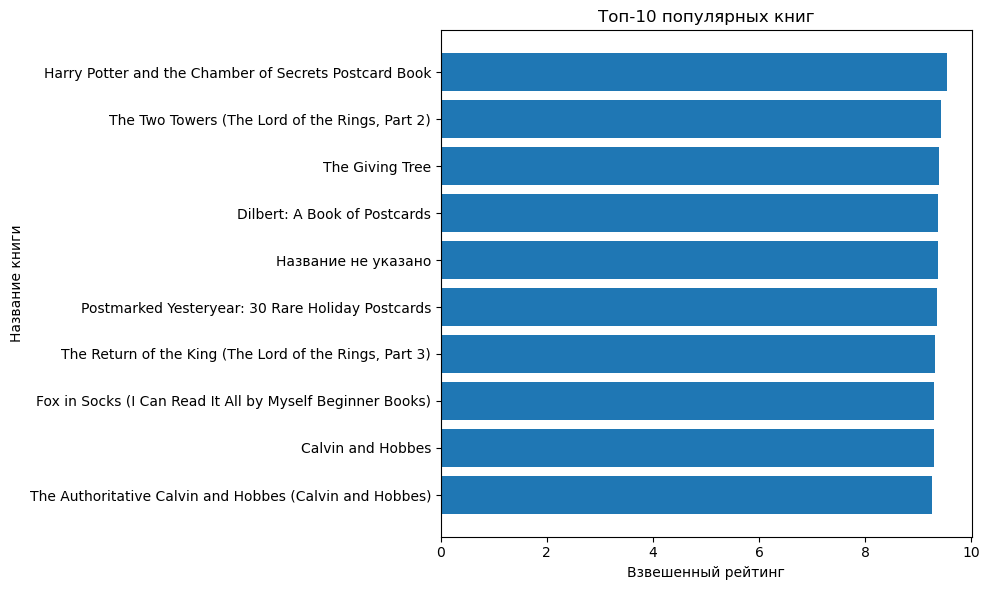

In [60]:
top10 = top_books.head(10).sort_values("weighted_rating")
plt.figure(figsize=(10, 6))
plt.barh(top10["Book-Title"], top10["weighted_rating"])
plt.xlabel("Взвешенный рейтинг")
plt.ylabel("Название книги")
plt.title("Топ-10 популярных книг")
plt.tight_layout()
plt.show()

In [61]:
MIN_BOOK_RATINGS = 40
MIN_USER_RATINGS = 30
MAX_BOOKS_FOR_MODEL = 12000

book_counts = ratings_clean["ISBN"].value_counts()
user_counts = ratings_clean["User-ID"].value_counts()

selected_isbns = book_counts[book_counts >= MIN_BOOK_RATINGS].index
selected_users = user_counts[user_counts >= MIN_USER_RATINGS].index

model_ratings = ratings_clean[
    ratings_clean["ISBN"].isin(selected_isbns) &
    ratings_clean["User-ID"].isin(selected_users)
].copy()

top_isbns = model_ratings["ISBN"].value_counts().head(MAX_BOOKS_FOR_MODEL).index
model_ratings = model_ratings[model_ratings["ISBN"].isin(top_isbns)]

book_user = model_ratings.pivot_table(
    index="ISBN", columns="User-ID", values="Book-Rating", fill_value=0
)

book_user_sparse = csr_matrix(book_user.values)

print("Размер матрицы (книги × пользователи):", book_user.shape)
print("Ненулевых оценок:", book_user_sparse.nnz)

Размер матрицы (книги × пользователи): (754, 2122)
Ненулевых оценок: 23299


In [62]:
neighbors_model = NearestNeighbors(metric="cosine", algorithm="brute")
neighbors_model.fit(book_user_sparse)

book_info = books_clean.set_index("ISBN")
isbn_to_title = book_info["Book-Title"].to_dict()
title_to_isbns = (
    books_clean.groupby("Book-Title")["ISBN"].apply(list).to_dict()
)

def find_similar_books(book_title, n=10):
    """Возвращает книги, похожие на указанную, по оценкам пользователей."""
    if book_title not in title_to_isbns:
        print(f"Книга «{book_title}» не найдена в каталоге.")
        return pd.DataFrame()

    candidate_isbns = [isbn for isbn in title_to_isbns[book_title] if isbn in book_user.index]
    if not candidate_isbns:
        print("Для этой книги недостаточно оценок, чтобы найти похожие.")
        return pd.DataFrame()

    isbn = candidate_isbns[0]
    row_index = book_user.index.get_loc(isbn)
    distances, indices = neighbors_model.kneighbors(
        book_user_sparse[row_index], n_neighbors=min(n + 1, book_user.shape[0])
    )

    result = []
    for distance, index in zip(distances[0], indices[0]):
        similar_isbn = book_user.index[index]
        if similar_isbn == isbn:
            continue
        result.append({
            "Название": isbn_to_title.get(similar_isbn, "Название не указано"),
            "Автор": book_info.loc[similar_isbn, "Book-Author"] if similar_isbn in book_info.index else "Автор не указан",
            "Сходство": round(1 - float(distance), 3)
        })
        if len(result) >= n:
            break

    return pd.DataFrame(result)

In [63]:
find_similar_books("The Hobbit", n=10)

Для этой книги недостаточно оценок, чтобы найти похожие.


""


In [64]:
user_book_ratings = model_ratings.copy()
book_average = model_ratings.groupby("ISBN")["Book-Rating"].mean()
book_vote_count = model_ratings.groupby("ISBN")["Book-Rating"].count()

def recommend_for_user(user_id, n=10):
    """Предлагает пользователю популярные книги, которые он ещё не оценивал."""
    user_id = int(user_id)

    user_rows = user_book_ratings[user_book_ratings["User-ID"] == user_id]
    if user_rows.empty:
        print(f"Пользователь {user_id} не найден в отфильтрованных данных.")
        return pd.DataFrame()

    already_rated = set(user_rows["ISBN"])
    candidates = book_average[~book_average.index.isin(already_rated)].to_frame("Средняя оценка")
    candidates["Количество оценок"] = book_vote_count
    candidates = candidates[candidates["Количество оценок"] >= 5]
    candidates = candidates.sort_values(
        ["Средняя оценка", "Количество оценок"], ascending=False
    ).head(n)

    candidates = candidates.reset_index().rename(columns={"ISBN": "ISBN"})
    candidates["Название"] = candidates["ISBN"].map(isbn_to_title)
    candidates["Автор"] = candidates["ISBN"].map(
        books_clean.drop_duplicates("ISBN").set_index("ISBN")["Book-Author"].to_dict()
    )
    return candidates[["Название", "Автор", "Средняя оценка", "Количество оценок"]]

In [65]:
example_user_id = int(model_ratings["User-ID"].iloc[0])
print("Пример ID пользователя:", example_user_id)
recommend_for_user(example_user_id, n=10)

Пример ID пользователя: 277427


,Название,Автор,Средняя оценка,Количество оценок
0,"The Return of the King (The Lord of the Rings, Part 3)",J.R.R. TOLKIEN,9.425000,40
1,Harry Potter and the Goblet of Fire (Book 4),J. K. Rowling,9.300000,80
2,Harry Potter and the Sorcerer's Stone (Book 1),J. K. Rowling,9.285714,21
3,The Rescue,Nicholas Sparks,9.272727,11
4,Gone with the Wind,Margaret Mitchell,9.269231,26
5,Where the Red Fern Grows,Wilson Rawls,9.269231,26
6,Charlotte's Web (Trophy Newbery),E. B. White,9.264706,34
7,Harry Potter and the Prisoner of Azkaban (Book 3),J. K. Rowling,9.216867,83
8,"The Two Towers (The Lord of the Rings, Part 2)",J.R.R. TOLKIEN,9.205128,39
9,"Tuesdays with Morrie: An Old Man, a Young Man, and Life's Greatest Lesson",Mitch Albom,9.200000,10


In [66]:
print("Всего книг в исходном файле:", len(books))
print("Всего оценок в исходном файле:", len(ratings))
print("Книг после подготовки:", len(books_clean))
print("Оценок, использованных в модели похожих книг:", len(model_ratings))
print("Книг в модели:", book_user.shape[0])
print("Пользователей в модели:", book_user.shape[1])

Всего книг в исходном файле: 271360
Всего оценок в исходном файле: 1149780
Книг после подготовки: 271359
Оценок, использованных в модели похожих книг: 23299
Книг в модели: 754
Пользователей в модели: 2122
